In [25]:
import numpy as np
import pandas as pd

In [26]:
df1 = pd.read_csv("sms_data/spam_ham_india.csv")

In [27]:
df2 = pd.read_csv("sms_data/spam_utf8.csv")

In [28]:
df1.sample(5)

,Msg,Label
639,*THE ART OF LIVING*,ham
2117,Ty,ham
1989,I gv hind copper in plenty.,ham
131,I look forward to your performance,ham
1258,SMSPHARMA is now up 3% which is already a good...,ham


In [29]:
df2.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5376,ham,I don't want you to leave. But i'm barely doin...,NaN,NaN,NaN
4949,ham,Hi its me you are probably having too much fun...,NaN,NaN,NaN
3250,ham,"I‰Û÷ll leave around four, ok?",NaN,NaN,NaN
4081,ham,No no. I will check all rooms befor activities,NaN,NaN,NaN
3285,ham,Not to worry. I'm sure you'll get it.,NaN,NaN,NaN


In [30]:
df1.shape

(2267, 2)

In [31]:
df2.shape

(5572, 5)

In [32]:
df2 = df2.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis = 1)

In [33]:
df2.sample(5)

,v1,v2
120,spam,URGENT! Your Mobile No. was awarded å£2000 Bon...
2136,ham,Well done and ! luv ya all
1021,spam,Guess what! Somebody you know secretly fancies...
2640,ham,Pandy joined 4w technologies today.he got job..
3842,ham,Yes ammae....life takes lot of turns you can o...


In [34]:
df2.rename(columns={"v1": "Label", "v2" : "Msg"}, inplace=True)

In [35]:
df2.head()

,Label,Msg
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [36]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2267 entries, 0 to 2266
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Msg     2266 non-null   object
 1   Label   2267 non-null   object
dtypes: object(2)
memory usage: 35.6+ KB


In [37]:
df1.isnull().sum()

Msg      1
Label    0
dtype: int64

In [40]:
df2.isnull().sum()

Label    0
Msg      0
dtype: int64

In [43]:
df1.duplicated().sum()

204

In [42]:
df2.duplicated().sum()

403

In [44]:
df1 = df1.dropna(subset=['Msg'])

In [45]:
df1.isnull().sum()

Msg      0
Label    0
dtype: int64

In [46]:
df1 = df1.drop_duplicates()
df2 = df2.drop_duplicates()

df1 = df1.reset_index(drop=True)
df2 = df2.reset_index(drop=True)

In [50]:
df1.shape

(2062, 2)

In [51]:
df2.shape

(5169, 2)

In [52]:
print("Duplicate messages in df1:", df1['Msg'].duplicated().sum())
print("Duplicate messages in df2:", df2['Msg'].duplicated().sum())

Duplicate messages in df1: 0
Duplicate messages in df2: 0


In [62]:
df = pd.concat([df1, df2], ignore_index=True)

In [63]:
df.sample(10)

,Msg,Label
6805,I wont do anything de.,ham
6021,\The world suffers a lot... Not because of the...,ham
5686,"Dont worry, 1 day very big lambu ji vl come..t...",ham
1601,Athmave Poo is now on Wynk Music App. Don't mi...,spam
3470,"That's good, because I need drugs",ham
1405,Tired of cable disruptions? Switch to Airtel D...,spam
2093,Yeah he got in at 2 and was v apologetic. n ha...,ham
2491,"Ask g or iouri, I've told the story like ten t...",ham
6862,No problem with the renewal. I.ll do it right ...,ham
5970,"Dear Voucher Holder, To claim this weeks offer...",spam


In [64]:
df.shape

(7231, 2)

In [65]:
df.isnull().sum()

Msg      0
Label    0
dtype: int64

In [66]:
df.duplicated().sum()

1

In [67]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [68]:
df.duplicated().sum()

0

In [17]:
# 1. Data cleaning
# 2. EDA
# 3. Text Preprocessing
# 4. Model building
# 5. Evaluation
# 6. Improvement
# 7. Website
# 8. Deploy

## 1. Data Cleaning

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7230 entries, 0 to 7229
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Msg     7230 non-null   object
 1   Label   7230 non-null   object
dtypes: object(2)
memory usage: 113.1+ KB


In [70]:
df.sample(5)

,Msg,Label
4960,Webpage s not available!,ham
989,Even I came my home town Last week,ham
6106,Sorry . I will be able to get to you. See you ...,ham
514,Thanks; rebooting my laptop fixed,ham
94,Not required now,ham


In [71]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [72]:
df['Label'] = encoder.fit_transform(df['Label'])

In [73]:
df.head()

,Msg,Label
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1
1,Hi! Thank you for being with Vi-India's FASTES...,1
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1
3,I will try to manage took tablets,0
4,Study from Home with Vi!! Watch Kite Victers C...,1


In [76]:
df.shape

(7230, 2)

## 2.EDA

In [77]:
df["Label"].value_counts()

Label
0    5841
1    1389
Name: count, dtype: int64

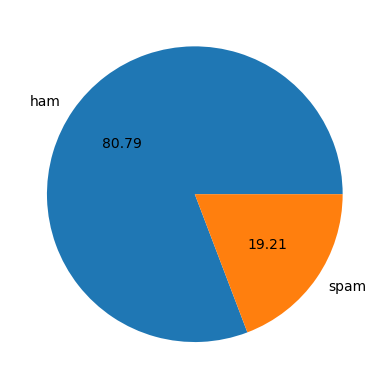

In [78]:
import matplotlib.pyplot as plt
plt.pie(df['Label'].value_counts(), labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [34]:
# Data is imbalanced

In [108]:
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to C:\Users\AGNIV
[nltk_data]     GHOSH\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\AGNIV
[nltk_data]     GHOSH\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\AGNIV
[nltk_data]     GHOSH\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [88]:
df['num_characters'] = df['Msg'].apply(len)

In [89]:
df.head()

,Msg,Label,num_characters
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103
1,Hi! Thank you for being with Vi-India's FASTES...,1,151
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145
3,I will try to manage took tablets,0,33
4,Study from Home with Vi!! Watch Kite Victers C...,1,140


In [90]:
# num of words
df['num_words'] = df['Msg'].apply(lambda x:len(nltk.word_tokenize(x)))

In [91]:
df.head()

,Msg,Label,num_characters,num_words
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103,17
1,Hi! Thank you for being with Vi-India's FASTES...,1,151,30
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145,27
3,I will try to manage took tablets,0,33,7
4,Study from Home with Vi!! Watch Kite Victers C...,1,140,28


In [92]:
df['num_sentences'] = df['Msg'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [93]:
df.head()

,Msg,Label,num_characters,num_words,num_sentences
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103,17,4
1,Hi! Thank you for being with Vi-India's FASTES...,1,151,30,4
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145,27,2
3,I will try to manage took tablets,0,33,7,1
4,Study from Home with Vi!! Watch Kite Victers C...,1,140,28,4


In [94]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,7230.000000,7230.000000,7230.000000
mean,86.526556,19.029737,1.956017
std,72.280990,15.198382,1.683162
min,1.000000,1.000000,1.000000
25%,35.000000,8.000000,1.000000
50%,64.000000,15.000000,1.000000
75%,133.000000,27.000000,3.000000
max,910.000000,220.000000,52.000000


In [96]:
# ham
df[df['Label'] == 0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5841.000000,5841.000000,5841.000000
mean,70.793357,16.420134,1.706557
std,67.773439,14.733994,1.294154
min,1.000000,1.000000,1.000000
25%,31.000000,8.000000,1.000000
50%,50.000000,12.000000,1.000000
75%,87.000000,21.000000,2.000000
max,910.000000,220.000000,38.000000


In [97]:
#spam
df[df['Label'] == 1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,1389.000000,1389.000000,1389.000000
mean,152.687545,30.003600,3.005040
std,49.622599,11.852084,2.518943
min,13.000000,2.000000,1.000000
25%,135.000000,25.000000,2.000000
50%,151.000000,29.000000,3.000000
75%,159.000000,33.000000,4.000000
max,635.000000,193.000000,52.000000


In [98]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

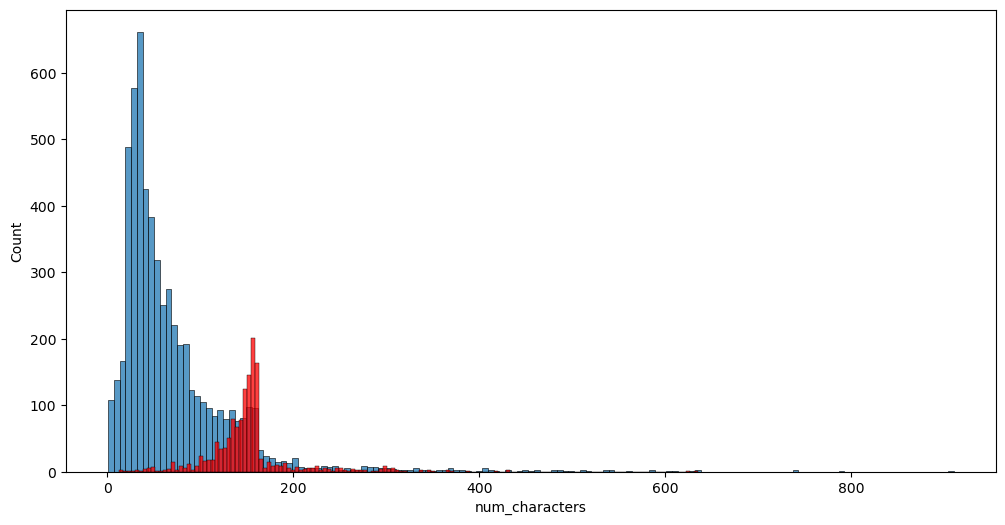

In [99]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['Label'] == 0]['num_characters'])
sns.histplot(df[df['Label'] == 1]['num_characters'],color='red')

<Axes: xlabel='num_words', ylabel='Count'>

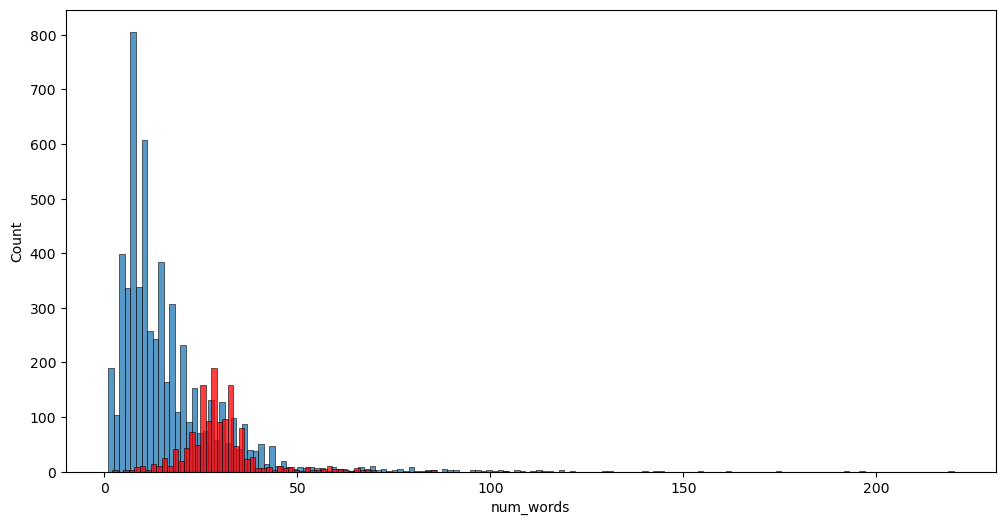

In [100]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['Label'] == 0]['num_words'])
sns.histplot(df[df['Label'] == 1]['num_words'],color='red')

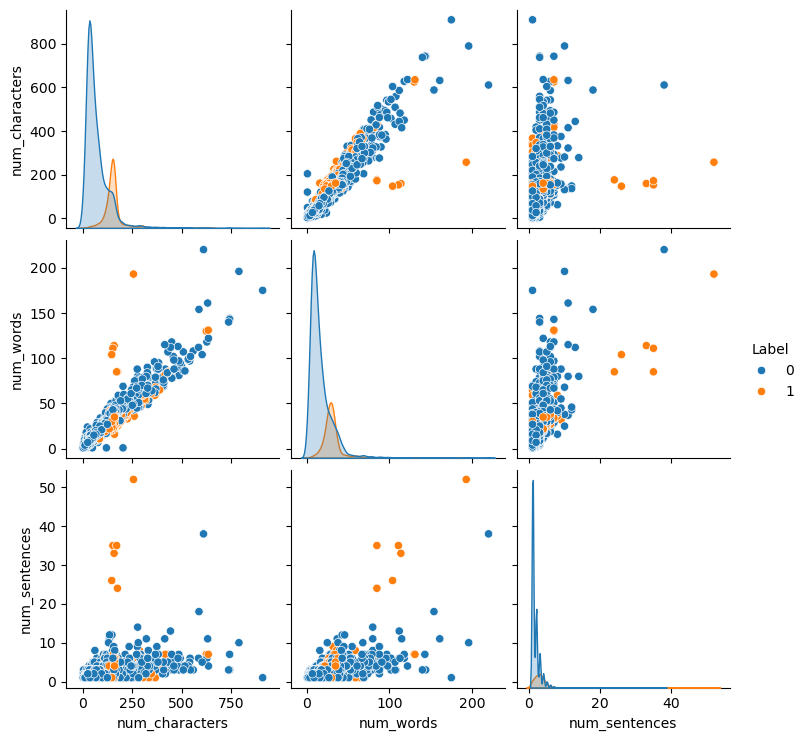

In [101]:
sns.pairplot(df,hue='Label')

## 3. Data Preprocessing
- Lower case
- Tokenization
- Removing special characters
- Removing stop words and punctuation
- Stemming

In [124]:
STOPWORDS = set(stopwords.words('english'))
def transform_text(text):
    
    text = text.lower()
    
    # Tokenization
    text = nltk.word_tokenize(text)
    
    # Keep only alphanumeric words
    text = [word for word in text if word.isalnum()]
    
    # Remove stopwords
    text = [word for word in text if word not in STOPWORDS]
    
    # Stemming
    text = [ps.stem(word) for word in text]
    
    return " ".join(text)

In [125]:
transform_text(
    "Don't let security concerns ruin your travel plans! Get Airtel Xsafe- Wi-Fi enabled surveillance solution that sends real time alerts. Order now and get FREE installation i.airtel.in/PreEye"
)

'let secur concern ruin travel plan get airtel enabl surveil solut send real time alert order get free instal'

In [114]:
df['Msg'][10]

"Don't let security concerns ruin your travel plans! Get Airtel Xsafe- Wi-Fi enabled surveillance solution that sends real time alerts. Order now and get FREE installation i.airtel.in/PreEye"

In [126]:
ps = PorterStemmer()
ps.stem('loving')

'love'

In [113]:
df['transformed_text'] = df['Msg'].apply(transform_text)

In [117]:
df.head()

,Msg,Label,num_characters,num_words,num_sentences,transformed_text
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103,17,4,congratul free 2gb data claim airtel thank app...
1,Hi! Thank you for being with Vi-India's FASTES...,1,151,30,4,hi thank fastest 4g love improv click http sha...
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145,27,2,part cyber swachhta pakhwada goi advis keep di...
3,I will try to manage took tablets,0,33,7,1,tri manag took tablet
4,Study from Home with Vi!! Watch Kite Victers C...,1,140,28,4,studi home vi watch kite victer channel free m...


In [118]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [119]:
spam_wc = wc.generate(df[df['Label'] == 1]['transformed_text'].str.cat(sep=" "))

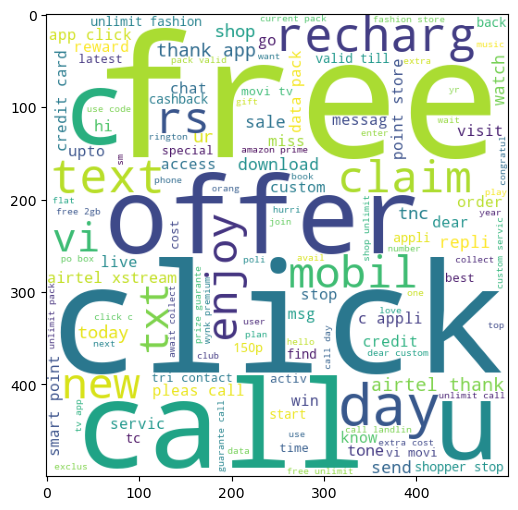

In [120]:
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)

In [121]:
ham_wc = wc.generate(df[df['Label'] == 0]['transformed_text'].str.cat(sep=" "))

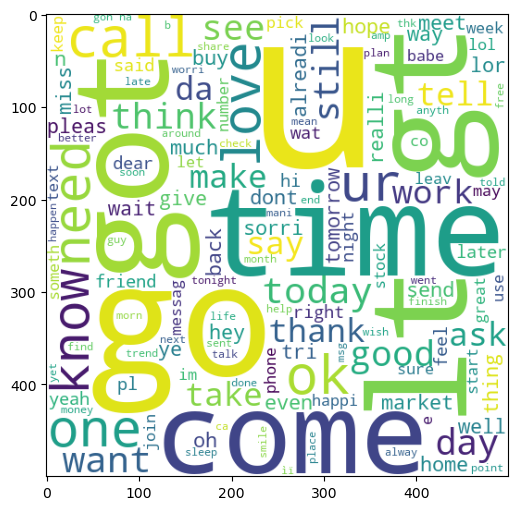

In [122]:
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)

In [123]:
df.head()

,Msg,Label,num_characters,num_words,num_sentences,transformed_text
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103,17,4,congratul free 2gb data claim airtel thank app...
1,Hi! Thank you for being with Vi-India's FASTES...,1,151,30,4,hi thank fastest 4g love improv click http sha...
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145,27,2,part cyber swachhta pakhwada goi advis keep di...
3,I will try to manage took tablets,0,33,7,1,tri manag took tablet
4,Study from Home with Vi!! Watch Kite Victers C...,1,140,28,4,studi home vi watch kite victer channel free m...


In [132]:
spam_corpus = []

for msg in df[df['Label'] == 1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

len(spam_corpus)

22501

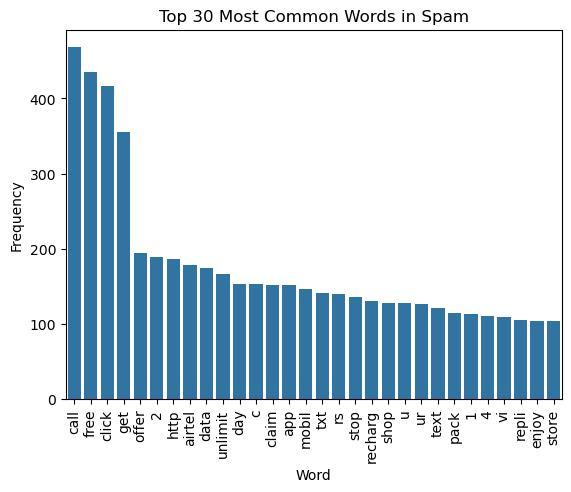

In [135]:
from collections import Counter

spam_corpus = []

for msg in df[df['Label'] == 1]['transformed_text']:
    spam_corpus.extend(msg.split())

spam_words = Counter(spam_corpus).most_common(30)

spam_words_df = pd.DataFrame(spam_words, columns=['Word', 'Frequency'])

sns.barplot(
    data=spam_words_df,
    x='Word',
    y='Frequency'
)

plt.xticks(rotation='vertical')
plt.title("Top 30 Most Common Words in Spam")
plt.show()

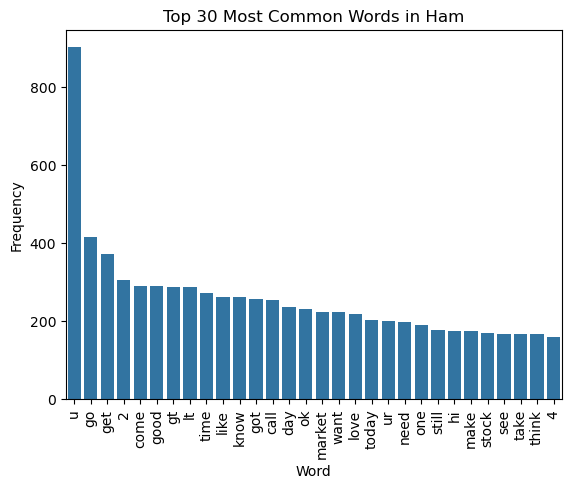

In [136]:
ham_corpus = []

for msg in df[df['Label'] == 0]['transformed_text']:
    ham_corpus.extend(msg.split())

ham_words = Counter(ham_corpus).most_common(30)

ham_words_df = pd.DataFrame(
    ham_words,
    columns=['Word', 'Frequency']
)

sns.barplot(
    data=ham_words_df,
    x='Word',
    y='Frequency'
)

plt.xticks(rotation='vertical')
plt.title("Top 30 Most Common Words in Ham")
plt.show()

In [137]:
len(ham_corpus)

44587

In [139]:
# Text Vectorization
# using Bag of Words
df.head()

,Msg,Label,num_characters,num_words,num_sentences,transformed_text
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,1,103,17,4,congratul free 2gb data claim airtel thank app...
1,Hi! Thank you for being with Vi-India's FASTES...,1,151,30,4,hi thank fastest 4g love improv click http sha...
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",1,145,27,2,part cyber swachhta pakhwada goi advis keep di...
3,I will try to manage took tablets,0,33,7,1,tri manag took tablet
4,Study from Home with Vi!! Watch Kite Victers C...,1,140,28,4,studi home vi watch kite victer channel free m...


## 4. Model Building

In [140]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

In [141]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [142]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [143]:
# appending the num_character col to X
X = np.hstack((X,df['num_characters'].values.reshape(-1,1)))

In [144]:
X.shape

(7230, 3001)

In [145]:
y = df['Label'].values

In [146]:
from sklearn.model_selection import train_test_split

In [147]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2,stratify = y)

In [148]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [149]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [150]:
gnb.fit(X_train,y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))

0.84716459197787
[[961 207]
 [ 14 264]]
0.5605095541401274


In [151]:
mnb.fit(X_train,y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9847856154910097
[[1161    7]
 [  15  263]]
0.9740740740740741


In [152]:
bnb.fit(X_train,y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.983402489626556
[[1163    5]
 [  19  259]]
0.9810606060606061


In [157]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [158]:
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50,random_state=2)

In [159]:
clfs = {
    'SVC' : svc,
    'KN' : knc, 
    'NB': mnb, 
    'DT': dtc, 
    'LR': lrc, 
    'RF': rfc, 
    'AdaBoost': abc, 
    'BgC': bc, 
    'ETC': etc,
    'GBDT':gbdt
}

In [167]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    training_accuracy = clf.score(X_train,y_train)
    testing_accuracy = clf.score(X_test,y_test)
    return accuracy,precision,training_accuracy,testing_accuracy

In [170]:
accuracy_scores = []
precision_scores = []
training_scores = []
testing_scores = []
for name,clf in clfs.items():
    
    current_accuracy,current_precision,current_training_score,current_testing_score = train_classifier(clf, X_train,y_train,X_test,y_test)
    
    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)
    print("Training Score - ",current_training_score)
    print("Testing Score - ",current_testing_score)
    
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)
    training_scores.append(current_training_score)
    testing_scores.append(current_testing_score)

For  SVC
Accuracy -  0.8070539419087137
Precision -  0.0
Training Score -  0.806881051175657
Testing Score -  0.8070539419087137
For  KN
Accuracy -  0.8478561549100968
Precision -  0.7589285714285714
Training Score -  0.8896957123098201
Testing Score -  0.8478561549100968
For  NB
Accuracy -  0.9847856154910097
Precision -  0.9740740740740741
Training Score -  0.9835753803596127
Testing Score -  0.9847856154910097
For  DT
Accuracy -  0.9363762102351314
Precision -  0.9345794392523364
Training Score -  0.9386237897648686
Testing Score -  0.9363762102351314
For  LR
Accuracy -  0.9702627939142462
Precision -  0.9681274900398407
Training Score -  0.9806362378976486
Testing Score -  0.9702627939142462
For  RF
Accuracy -  0.9813278008298755
Precision -  0.9883268482490273
Training Score -  0.9994813278008299
Testing Score -  0.9813278008298755


C:\Users\AGNIV GHOSH\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


For  AdaBoost
Accuracy -  0.9633471645919779
Precision -  0.9310344827586207
Training Score -  0.9759681881051175
Testing Score -  0.9633471645919779
For  BgC
Accuracy -  0.9681881051175657
Precision -  0.9360902255639098
Training Score -  0.9994813278008299
Testing Score -  0.9681881051175657
For  ETC
Accuracy -  0.983402489626556
Precision -  0.9922480620155039
Training Score -  0.9996542185338866
Testing Score -  0.983402489626556
For  GBDT
Accuracy -  0.9557399723374828
Precision -  0.9458333333333333
Training Score -  0.9640387275242047
Testing Score -  0.9557399723374828


In [171]:
performance_df = pd.DataFrame({
    'Algorithm':clfs.keys(),
    'Accuracy':accuracy_scores,
    'Precision':precision_scores,
    'Training Score' : training_scores,
    'Testing Score' : testing_scores}).sort_values('Precision',ascending=False)

In [172]:
performance_df

,Algorithm,Accuracy,Precision,Training Score,Testing Score
8,ETC,0.983402,0.992248,0.999654,0.983402
5,RF,0.981328,0.988327,0.999481,0.981328
2,NB,0.984786,0.974074,0.983575,0.984786
4,LR,0.970263,0.968127,0.980636,0.970263
9,GBDT,0.955740,0.945833,0.964039,0.955740
7,BgC,0.968188,0.936090,0.999481,0.968188
3,DT,0.936376,0.934579,0.938624,0.936376
6,AdaBoost,0.963347,0.931034,0.975968,0.963347
1,KN,0.847856,0.758929,0.889696,0.847856
0,SVC,0.807054,0.000000,0.806881,0.807054


In [173]:
performance_df1 = pd.melt(performance_df, id_vars = "Algorithm")

In [174]:
performance_df1

,Algorithm,variable,value
0,ETC,Accuracy,0.983402
1,RF,Accuracy,0.981328
2,NB,Accuracy,0.984786
3,LR,Accuracy,0.970263
4,GBDT,Accuracy,0.955740
5,BgC,Accuracy,0.968188
6,DT,Accuracy,0.936376
7,AdaBoost,Accuracy,0.963347
8,KN,Accuracy,0.847856
9,SVC,Accuracy,0.807054


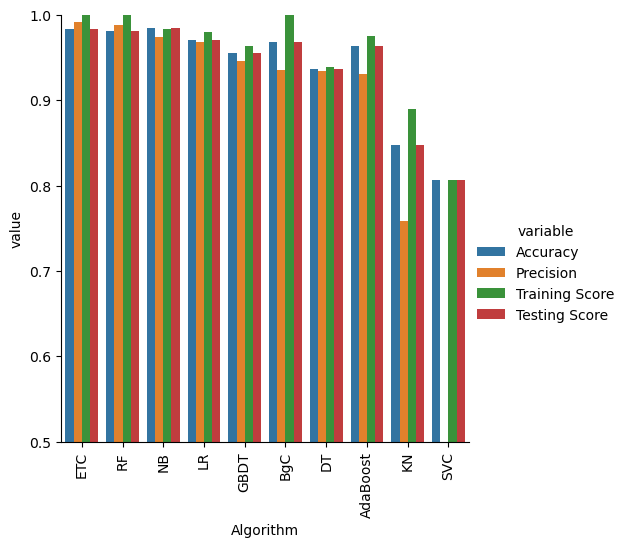

In [175]:
sns.catplot(x = 'Algorithm', y='value', 
               hue = 'variable',data=performance_df1, kind='bar',height=5)
plt.ylim(0.5,1.0)
plt.xticks(rotation='vertical')
plt.show()

In [ ]:
# model improve
# 1. Change the max_features parameter of TfIdf

In [176]:
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_max_ft_3000':accuracy_scores,'Precision_max_ft_3000':precision_scores}).sort_values('Precision_max_ft_3000',ascending=False)

In [177]:
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_scaling':accuracy_scores,'Precision_scaling':precision_scores}).sort_values('Precision_scaling',ascending=False)

In [178]:
new_df = performance_df.merge(temp_df,on='Algorithm')

In [179]:
new_df_scaled = new_df.merge(temp_df,on='Algorithm')

In [180]:
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_num_chars':accuracy_scores,'Precision_num_chars':precision_scores}).sort_values('Precision_num_chars',ascending=False)

In [181]:
new_df_scaled.merge(temp_df,on='Algorithm')

,Algorithm,Accuracy,Precision,Training Score,Testing Score,Accuracy_scaling_x,Precision_scaling_x,Accuracy_scaling_y,Precision_scaling_y,Accuracy_num_chars,Precision_num_chars
0,ETC,0.983402,0.992248,0.999654,0.983402,0.983402,0.992248,0.983402,0.992248,0.983402,0.992248
1,RF,0.981328,0.988327,0.999481,0.981328,0.981328,0.988327,0.981328,0.988327,0.981328,0.988327
2,NB,0.984786,0.974074,0.983575,0.984786,0.984786,0.974074,0.984786,0.974074,0.984786,0.974074
3,LR,0.970263,0.968127,0.980636,0.970263,0.970263,0.968127,0.970263,0.968127,0.970263,0.968127
4,GBDT,0.955740,0.945833,0.964039,0.955740,0.955740,0.945833,0.955740,0.945833,0.955740,0.945833
5,BgC,0.968188,0.936090,0.999481,0.968188,0.968188,0.936090,0.968188,0.936090,0.968188,0.936090
6,DT,0.936376,0.934579,0.938624,0.936376,0.936376,0.934579,0.936376,0.934579,0.936376,0.934579
7,AdaBoost,0.963347,0.931034,0.975968,0.963347,0.963347,0.931034,0.963347,0.931034,0.963347,0.931034
8,KN,0.847856,0.758929,0.889696,0.847856,0.847856,0.758929,0.847856,0.758929,0.847856,0.758929
9,SVC,0.807054,0.000000,0.806881,0.807054,0.807054,0.000000,0.807054,0.000000,0.807054,0.000000


In [184]:
# Voting Classifier
RFC = RandomForestClassifier(n_estimators=50, random_state=2)
MNB = MultinomialNB()
ETC = ExtraTreesClassifier(n_estimators=50, random_state=2)

from sklearn.ensemble import VotingClassifier

In [186]:
voting = VotingClassifier(estimators=[('rfc', RFC), ('nb', MNB), ('et', ETC)],voting='soft')

In [187]:
voting.fit(X_train,y_train)

VotingClassifier(estimators=[('rfc',
                              RandomForestClassifier(n_estimators=50,
                                                     random_state=2)),
                             ('nb', MultinomialNB()),
                             ('et',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2))],
                 voting='soft')

In [193]:
y_pred = voting.predict(X_test)
print("Accuracy",accuracy_score(y_test,y_pred))
print("Precision",precision_score(y_test,y_pred))
print("Training Score",voting.score(X_train,y_train))
print("Testing Score",voting.score(X_test,y_test))

Accuracy 0.9861687413554634
Precision 0.9923664122137404
Training Score 0.9996542185338866
Testing Score 0.9861687413554634


In [194]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(voting,open('model.pkl','wb'))